# ML Assignment 4 – Gradient Descent
**Problem Statement:** Implement Gradient Descent Algorithm to find the local minima of a function. For example, find the local minima of the function y = (x+3)² starting from the point x = 2.

Derivative: dy/dx = 2(x+3). Update rule: x = x − learning_rate × dy/dx. True minimum is at x = −3, y = 0.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def f(x):
    return (x + 3) ** 2

def df(x):
    return 2 * (x + 3)

In [3]:
cur_x = 2              # starting point
rate = 0.01            # learning rate
precision = 0.000001   # stop when the step becomes this small
max_iters = 10000
iters = 0
step = 1
history = [cur_x]

while step > precision and iters < max_iters:
    prev_x = cur_x
    cur_x = cur_x - rate * df(prev_x)
    step = abs(cur_x - prev_x)
    iters += 1
    history.append(cur_x)

print('Iterations:', iters)
print('Local minimum occurs at x =', round(cur_x, 4))
print('Minimum value y =', round(f(cur_x), 6))

Iterations: 571
Local minimum occurs at x = -3.0
Minimum value y = 0.0


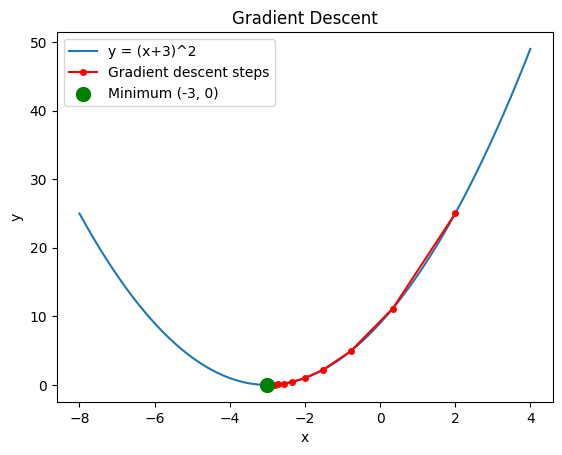

In [4]:
x = np.linspace(-8, 4, 200)
plt.plot(x, f(x), label='y = (x+3)^2')
h = np.array(history[::20])
plt.plot(h, f(h), 'ro-', markersize=4, label='Gradient descent steps')
plt.scatter([-3], [0], color='green', s=100, zorder=5, label='Minimum (-3, 0)')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.title('Gradient Descent'); plt.show()

In [5]:
# Effect of learning rate
for lr in [0.001, 0.01, 0.1, 0.5]:
    x_, n = 2, 0
    while abs(lr * df(x_)) > precision and n < max_iters:
        x_ -= lr * df(x_); n += 1
    print(f'learning rate {lr:<6} -> x = {x_:.4f} after {n} iterations')

learning rate 0.001  -> x = -2.9995 after 4601 iterations
learning rate 0.01   -> x = -3.0000 after 570 iterations
learning rate 0.1    -> x = -3.0000 after 62 iterations
learning rate 0.5    -> x = -3.0000 after 1 iterations


**Conclusion:** Gradient descent converges to x ≈ −3 (y ≈ 0), the local (and global) minimum. A larger learning rate converges faster but too large a rate can overshoot.